In [1]:
import tensorflow as tf
from tensorflow.keras import layers, Model, optimizers

In [2]:
IMG_HEIGHT = 224
IMG_WIDTH  = 224
BATCH_SIZE = 16
EPOCHS     = 1
AUTOTUNE   = tf.data.AUTOTUNE


# 1) Loading + split


In [3]:

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    '../../data/leather/train',
    labels=None,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_split=0.2,
    subset='training',
    seed=42
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    '../../data/leather/train',
    labels=None,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_split=0.2,
    subset='validation',
    seed=42
)


Found 245 files.
Using 196 files for training.
Found 245 files.
Using 49 files for validation.


# 2) Normalize and prefetch


In [4]:
normalize = layers.Rescaling(1./255)
train_ds = train_ds.map(lambda x: (x, x),  num_parallel_calls=AUTOTUNE)
val_ds   = val_ds  .map(lambda x: (x, x),  num_parallel_calls=AUTOTUNE)


# 3) Model definition

In [5]:
class Autoencoder(Model):
    def __init__(self):
        super().__init__()
        # Encoder: 3× Conv → ReLU → AvgPool
        self.encoder = tf.keras.Sequential([
            layers.Conv2D(128, kernel_size=4, padding='same', activation='relu',
                          input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
            layers.AveragePooling2D(pool_size=2, strides=2),    # 224→112
            layers.Conv2D(256, kernel_size=4, padding='same', activation='relu'),
            layers.AveragePooling2D(pool_size=2, strides=2),    # 112→56
            layers.Conv2D(256, kernel_size=3, padding='same', activation='relu'),
            layers.AveragePooling2D(pool_size=2, strides=2),    #  56→28
        ])
        # Decoder: 3× ConvTranspose → ReLU (last: Sigmoid)
        self.decoder = tf.keras.Sequential([
            layers.Conv2DTranspose(256, kernel_size=4, strides=2, padding='same'),
            layers.ReLU(),                                      #  28→56
            layers.Conv2DTranspose(128, kernel_size=5, strides=2, padding='same'),
            layers.ReLU(),                                      #  56→112
            layers.Conv2DTranspose(3,   kernel_size=5, strides=2, padding='same',
                                   activation='sigmoid'),       # 112→224
        ])

    def call(self, x):
        x = self.encoder(x)
        return self.decoder(x)

model = Autoencoder()
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='mse'
)

/Users/vegardhaugerud/.pyenv/versions/3.11.4/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:99: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(


In [6]:
model.build(input_shape=(None, IMG_HEIGHT, IMG_WIDTH, 3))
model.summary()

/Users/vegardhaugerud/.pyenv/versions/3.11.4/lib/python3.11/site-packages/keras/src/layers/layer.py:360: UserWarning: `build()` was called on layer 'autoencoder', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │     1,120,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,120,896 (4.28 MB)

 Trainable params: 1,120,896 (4.28 MB)

 Non-trainable params: 0 (0.00 B)

# 4) Model saving

In [7]:
import os
from tensorflow.keras.callbacks import ModelCheckpoint


checkpoint_dir = "./checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_cb = ModelCheckpoint(
    filepath=os.path.join(checkpoint_dir,
                          "autoencoder_{epoch:02d}_val{val_loss:.4f}.keras"),
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,   # we’re saving the full model, not just weights
    verbose=1
)

# 5) Training


In [8]:
history = model.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    callbacks=[checkpoint_cb]
)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - loss: 5924.2881
Epoch 1: val_loss improved from inf to 5755.83057, saving model to ./checkpoints/autoencoder_01_val5755.8306.keras
13/13 ━━━━━━━━━━━━━━━━━━━━ 67s 5s/step - loss: 5919.5459 - val_loss: 5755.8306


In [35]:
x = tf.random.normal((1, IMG_HEIGHT, IMG_WIDTH, 3))
print('Output shape:', model(x).shape)

Output shape: (1, 224, 224, 3)


# 1) LOAD TEST SET

In [ ]:
raw_test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    '../data/leather/test',
    labels='inferred',
    label_mode='int',            # 0 or 1 per subfolder
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=1,
    shuffle=False
)
class_names = raw_test_ds.class_names
print("class_names:", class_names)  

normalize = tf.keras.layers.Rescaling(1./255)
test_ds = (
    raw_test_ds
     .map(lambda x,y: (normalize(x), y), num_parallel_calls=AUTOTUNE)
)

Found 124 files belonging to 6 classes.
class_names: ['color', 'cut', 'fold', 'glue', 'good', 'poke']


# 2) NORMALIZE


In [37]:
normalize = tf.keras.layers.Rescaling(1.0/255)
test_ds = test_ds.map(lambda x, y: (normalize(x), y),num_parallel_calls=AUTOTUNE)

import numpy as np

# 3) INFERENCE & ERROR COMPUTATION


In [38]:
import numpy as np
from tqdm import tqdm  # optional for a progress bar

errors = []
labels = []

for x_batch, y_batch in tqdm(test_ds, total=len(raw_test_ds)):
    x_rec = model(x_batch, training=False)
    # per‐image MSE over H×W×C → shape (1,)
    mse = tf.reduce_mean(tf.square(x_batch - x_rec), axis=[1,2,3])
    errors.append(mse.numpy()[0])
    labels.append(int(y_batch.numpy()[0]))

errors = np.array(errors)
labels = np.array(labels)

print(f"Test set size: {len(errors)} images")


100%|██████████| 124/124 [00:27<00:00,  4.57it/s]

Test set size: 124 images


# 4) Creating anomaly maps



In [ ]:
# gen_maps.py
import os
import numpy as np
from PIL import Image
import tifffile
import tensorflow as tf

# CONFIG — adjust these paths
DATASET_BASE = '../data'         # contains carpet/, hazelnut/, ...
OBJ           = 'leather'
MODEL_PATH    = 'checkpoints/ae_best.h5'        # or however you saved your TF model
OUT_BASE      = '../output/anomaly_maps'                  # will create anomaly_maps/carpet/...
IMG_SIZE      = (224, 224)

# 1) load your trained model

normalize = tf.keras.layers.Rescaling(1./255)

# 2) iterate test images
test_root = os.path.join(DATASET_BASE, OBJ, 'test')
for defect in os.listdir(test_root):            # defect = 'good' or 'hole'
    src_dir = os.path.join(test_root, defect)
    dst_dir = os.path.join(OUT_BASE, OBJ, 'test', defect)
    os.makedirs(dst_dir, exist_ok=True)

    for fname in os.listdir(src_dir):
        if not fname.lower().endswith('.png'):
            continue

        # load & preprocess
        img = Image.open(os.path.join(src_dir, fname)).convert('RGB')
        img = img.resize(IMG_SIZE)
        arr = np.array(img, dtype=np.float32)   # H×W×3, [0–255]
        arr = arr[None, ...]  # add batch dimension
        arr = normalize(arr)                    # → [0–1]

        # reconstruct & compute per-pixel MSE
        rec = model(arr, training=False).numpy()[0]  
        amap = np.mean((arr[0] - rec)**2, axis=-1)  # H×W

        # save as float32 TIFF
        out_path = os.path.join(dst_dir, fname.replace('.png','') + '.tiff')
        tifffile.imwrite(out_path, amap.astype(np.float32))

print("Done generating anomaly maps.")


Done generating anomaly maps.


# Running eval function


In [ ]:
import subprocess

def run_leather_evaluation():
    cmd = [
        "python", "../evaluate/patchCore_Eval/evaluate_experiment2.py",
        "--dataset_base_dir", "../data",
        "--anomaly_maps_dir", "../output/anomaly_maps",
        "--output_dir", "../output/metrics",
        "--evaluated_objects", "leather",
        "--pro_integration_limit", "0.3"
    ]
    subprocess.run(cmd, check=True)

if __name__ == "__main__":
    run_leather_evaluation()
    print("Evaluation completed successfully.")

=== Evaluate leather ===
Parsed 124 ground truth image files.
Read ground truth files and corresponding predictions...


100%|██████████| 124/124 [00:00<00:00, 340.91it/s]


Compute PRO curve...
Sort 6221824 anomaly scores...
AU-PRO (FPR limit: 0.3): 0.4353997761586689
Image-level classification AU-ROC: 0.9572010869565217


Wrote metrics to ../output/metrics.json
Evaluation completed successfully.


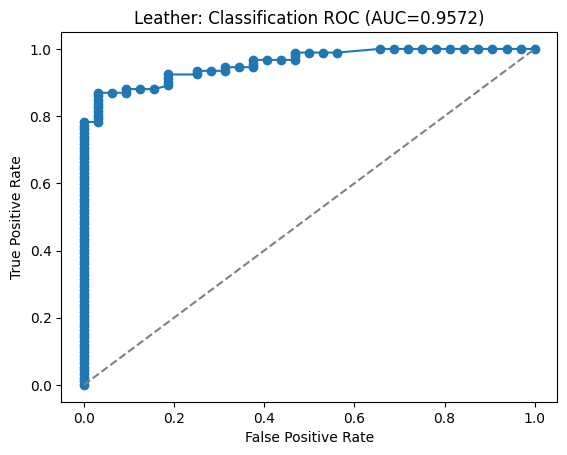

In [77]:
import matplotlib.pyplot as plt

fpr = [ 0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.0,
            0.03125,
            0.03125,
            0.03125,
            0.03125,
            0.03125,
            0.03125,
            0.03125,
            0.03125,
            0.03125,
            0.0625,
            0.09375,
            0.09375,
            0.125,
            0.15625,
            0.1875,
            0.1875,
            0.1875,
            0.1875,
            0.25,
            0.25,
            0.28125,
            0.3125,
            0.3125,
            0.34375,
            0.375,
            0.375,
            0.375,
            0.40625,
            0.4375,
            0.46875,
            0.46875,
            0.46875,
            0.5,
            0.53125,
            0.5625,
            0.65625,
            0.6875,
            0.71875,
            0.75,
            0.78125,
            0.8125,
            0.84375,
            0.875,
            0.90625,
            0.9375,
            0.96875,
            1.0]  # your "classification_roc_curve_fpr" list
tpr = [            0.0,
            0.010869565217391304,
            0.021739130434782608,
            0.03260869565217391,
            0.043478260869565216,
            0.05434782608695652,
            0.06521739130434782,
            0.07608695652173914,
            0.08695652173913043,
            0.09782608695652174,
            0.10869565217391304,
            0.11956521739130435,
            0.13043478260869565,
            0.14130434782608695,
            0.15217391304347827,
            0.16304347826086957,
            0.17391304347826086,
            0.18478260869565216,
            0.1956521739130435,
            0.20652173913043478,
            0.21739130434782608,
            0.22826086956521738,
            0.2391304347826087,
            0.25,
            0.2608695652173913,
            0.2717391304347826,
            0.2826086956521739,
            0.29347826086956524,
            0.30434782608695654,
            0.31521739130434784,
            0.32608695652173914,
            0.33695652173913043,
            0.34782608695652173,
            0.358695652173913,
            0.3695652173913043,
            0.3804347826086957,
            0.391304347826087,
            0.40217391304347827,
            0.41304347826086957,
            0.42391304347826086,
            0.43478260869565216,
            0.44565217391304346,
            0.45652173913043476,
            0.4673913043478261,
            0.4782608695652174,
            0.4891304347826087,
            0.5,
            0.5108695652173914,
            0.5217391304347826,
            0.532608695652174,
            0.5434782608695652,
            0.5543478260869565,
            0.5652173913043478,
            0.5760869565217391,
            0.5869565217391305,
            0.5978260869565217,
            0.6086956521739131,
            0.6195652173913043,
            0.6304347826086957,
            0.6413043478260869,
            0.6521739130434783,
            0.6630434782608695,
            0.6739130434782609,
            0.6847826086956522,
            0.6956521739130435,
            0.7065217391304348,
            0.717391304347826,
            0.7282608695652174,
            0.7391304347826086,
            0.75,
            0.7608695652173914,
            0.7717391304347826,
            0.782608695652174,
            0.782608695652174,
            0.7934782608695652,
            0.8043478260869565,
            0.8152173913043478,
            0.8260869565217391,
            0.8369565217391305,
            0.8478260869565217,
            0.8586956521739131,
            0.8695652173913043,
            0.8695652173913043,
            0.8695652173913043,
            0.8804347826086957,
            0.8804347826086957,
            0.8804347826086957,
            0.8913043478260869,
            0.9021739130434783,
            0.9130434782608695,
            0.9239130434782609,
            0.9239130434782609,
            0.9347826086956522,
            0.9347826086956522,
            0.9347826086956522,
            0.9456521739130435,
            0.9456521739130435,
            0.9456521739130435,
            0.9565217391304348,
            0.967391304347826,
            0.967391304347826,
            0.967391304347826,
            0.967391304347826,
            0.9782608695652174,
            0.9891304347826086,
            0.9891304347826086,
            0.9891304347826086,
            0.9891304347826086,
            1.0,
            1.0,
            1.0,
            1.0,
            1.0,
            1.0,
            1.0,
            1.0,
            1.0,
            1.0,
            1.0,
            1.0 ]  # your "classification_roc_curve_tpr" list

plt.plot(fpr, tpr, marker='o')
plt.plot([0,1], [0,1], '--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Leather: Classification ROC (AUC=0.9572)")
plt.show()